# VDUI Unit 4 - PPT 1 Activity

**Student Name:** A Sheiman Joshi  
**SRN:** PES2UG24CS003  
**Section:** Section A  
**Subject:** Visual Design and User Interface (UE24CS342AA9)  
**Unit:** Unit 4 - AI-Assisted and Advanced Visualization  


# Unit 4 · AI-Assisted Visualization — Demo Notebook
**Lecture 1: Automated Visualization** · Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

Everything here runs on a **synthetic retail dataset** generated in the notebook, so no downloads are needed.
Each section mirrors a topic from the lecture slides:

| # | Topic | What we build |
|---|-------|---------------|
| 1 | Automated visualization systems | Why automate, the 4-stage pipeline, evolution of systems |
| 2 | The automation pipeline | Type inference, aesthetics & scales, chart directory |
| 3 | Marks, channels, chart types | Expressiveness filter, channel ranking, Stevens' law, greedy encoding |
| 4 | Rule-based vs ML-based | Show Me rules, Draco costs, a tiny VizML-style model, Hit@k / MRR |
| 5 | Task- and data-aware | Task × Data table, task-aware scoring |
| 6 | Search & recommendation | Design-space counting, Voyager-style gallery |
| 7 | Text-to-chart | A LIDA-style pipeline with a *mock* LLM, and its failure modes |
| 8 | Advantages & limitations | Over-trust demo, human-in-the-loop checklist |
| 9 | Hands-on | The mini rule-based recommender from the slides |

In [1]:
import math, itertools, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20, "display.width", 140)

## 0 · The synthetic dataset
`BrightMart` is an imaginary retail chain. Each row is one order. We deliberately include the **traps** from the slides:
* `store_code` looks numeric but is an identifier (Wilke's *Station ID* trap),
* `month` is stored as text, so alphabetical order ≠ calendar order,
* `satisfaction` is ordinal (Low < Medium < High).

In [2]:
rng = np.random.default_rng(42)
n = 800

regions    = ["North", "South", "East", "West"]
categories = ["Electronics", "Grocery", "Fashion", "Home"]
store_codes = {"North": [1101, 1102, 1103], "South": [2201, 2202, 2203],
               "East":  [3301, 3302, 3303], "West":  [4401, 4402, 4403]}
price_base = {"Electronics": 520, "Grocery": 60, "Fashion": 140, "Home": 210}

order_date = pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D")
region = rng.choice(regions, n, p=[0.30, 0.30, 0.22, 0.18])
category = rng.choice(categories, n, p=[0.22, 0.38, 0.22, 0.18])
units = rng.integers(1, 9, n)
discount = rng.beta(2, 8, n) * 40                       # 0-40 %
unit_price = np.array([price_base[c] for c in category]) * rng.normal(1, 0.12, n)
season = 1 + 0.25 * np.sin((order_date.dayofyear - 80) / 365 * 2 * np.pi)
revenue = units * unit_price * (1 - discount / 100) * season
profit = revenue * (0.28 - 0.006 * discount + rng.normal(0, 0.04, n))
score = 2.0 + 0.012 * discount + rng.normal(0, 0.8, n) + (region == "South") * 0.35
satisfaction = pd.cut(score, [-np.inf, 1.6, 2.6, np.inf], labels=["Low", "Medium", "High"]).astype(str)

df = pd.DataFrame({
    "order_date": order_date,
    "month": order_date.strftime("%b"),
    "region": region,
    "store_code": [int(rng.choice(store_codes[r])) for r in region],
    "category": category,
    "satisfaction": satisfaction,
    "units": units,
    "discount_pct": discount.round(1),
    "revenue": revenue.round(2),
    "profit": profit.round(2),
}).sort_values("order_date").reset_index(drop=True)

df.head()

,order_date,month,region,store_code,category,satisfaction,units,discount_pct,revenue,profit
0,2025-01-02,Jan,North,1103,Home,Medium,8,7.7,1236.35,194.36
1,2025-01-02,Jan,North,1103,Fashion,Medium,2,3.2,219.05,48.56
2,2025-01-03,Jan,South,2201,Grocery,Medium,1,1.2,34.86,9.74
3,2025-01-03,Jan,North,1102,Home,High,4,5.2,666.07,162.62
4,2025-01-03,Jan,South,2201,Fashion,High,6,3.8,622.54,177.01


In [3]:
print(df.dtypes)
print()
print(df.describe(include="all").T[["count", "unique", "mean", "min", "max"]])

order_date      datetime64[us]
month                      str
region                     str
store_code               int64
category                   str
satisfaction               str
units                    int64
discount_pct           float64
revenue                float64
profit                 float64
dtype: object

              count unique                 mean                  min                  max
order_date      800    NaN  2025-07-04 12:21:36  2025-01-02 00:00:00  2025-12-31 00:00:00
month           800     12                  NaN                  NaN                  NaN
region          800      4                  NaN                  NaN                  NaN
store_code    800.0    NaN           2532.01375               1101.0               4403.0
category        800      4                  NaN                  NaN                  NaN
satisfaction    800      3                  NaN                  NaN                  NaN
units         800.0    NaN              4.321

---
# Topic 1 · Automated Visualization Systems
### 1.1 Why automate? One dataset, many possible charts
The design space is huge (Munzner §1.8, §1.11) and *most* of it is ineffective for a given task.
Below, the **same** question — *"how much revenue does each region bring in?"* — drawn four ways.

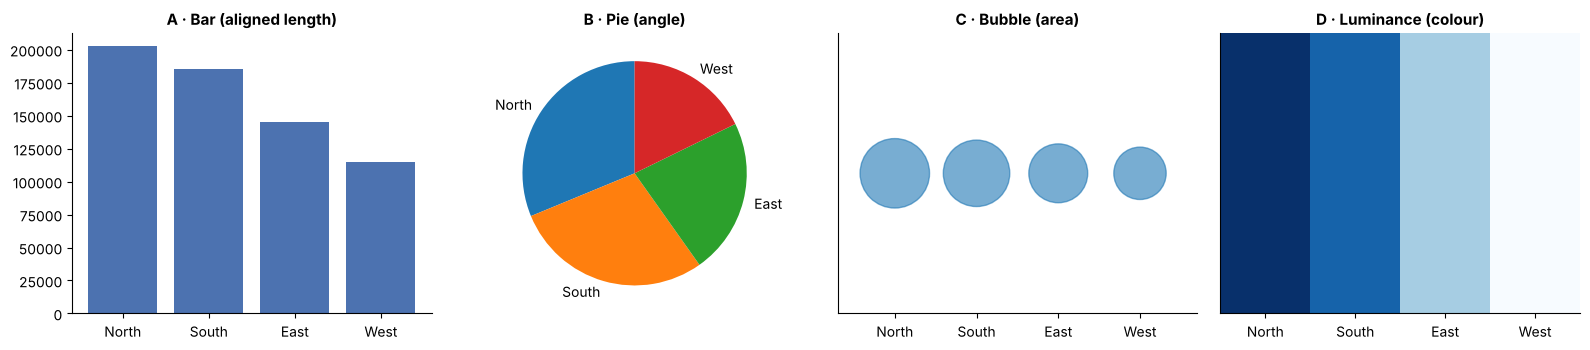

In [4]:
rev_by_region = df.groupby("region")["revenue"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))

# (a) bar: aligned length
ax[0].bar(rev_by_region.index, rev_by_region.values, color="#4C72B0")
ax[0].set_title("A · Bar (aligned length)")

# (b) pie: angle / area
ax[1].pie(rev_by_region.values, labels=rev_by_region.index, startangle=90)
ax[1].set_title("B · Pie (angle)")

# (c) bubble: area
ax[2].scatter(range(4), [1]*4, s=rev_by_region.values / rev_by_region.values.max() * 2500, alpha=.6)
ax[2].set_xticks(range(4)); ax[2].set_xticklabels(rev_by_region.index); ax[2].set_yticks([])
ax[2].set_xlim(-0.7, 3.7)
ax[2].set_title("C · Bubble (area)")

# (d) luminance ramp: a heat strip
ax[3].imshow([rev_by_region.values], cmap="Blues", aspect="auto")
ax[3].set_xticks(range(4)); ax[3].set_xticklabels(rev_by_region.index); ax[3].set_yticks([])
ax[3].set_title("D · Luminance (colour)")
plt.tight_layout(); plt.show()

Try to read off *which region is 1.5× bigger than another* — only chart A makes that easy.
That is the core idea: **let the computer enumerate and rank candidates, let the human judge.**

### 1.2 Definition: what an automated visualization system does
> Takes a dataset (and optionally the user's goal) and automatically **produces, ranks or refines** visualization designs — deciding *which fields*, *which marks & channels*, and *which chart type*.

### 1.3 Evolution of automated visualization

In [5]:
timeline = pd.DataFrame([
    (1986, "APT (Mackinlay)",            "Rules",              "First automatic designer; expressiveness + effectiveness"),
    (2007, "Show Me (Tableau)",          "Rules",              "Field selection -> recommended chart"),
    (2016, "Voyager / CompassQL",        "Search + rules",     "Gallery of ranked charts; faceted browsing"),
    (2019, "Draco",                      "Constraints",        "Hard + soft constraints, lowest cost wins"),
    (2019, "VizML",                      "ML (neural net)",    "Learn chart choice from ~1M Plotly charts"),
    (2019, "Data2Vis",                   "ML (seq2seq)",       "JSON rows -> Vega-Lite spec"),
    (2023, "LIDA",                       "LLM",                "Question + schema -> chart code"),
], columns=["Year", "System", "Knowledge encoded as", "Idea"])
timeline

,Year,System,Knowledge encoded as,Idea
0,1986,APT (Mackinlay),Rules,First automatic designer; expressiveness + eff...
1,2007,Show Me (Tableau),Rules,Field selection -> recommended chart
2,2016,Voyager / CompassQL,Search + rules,Gallery of ranked charts; faceted browsing
3,2019,Draco,Constraints,"Hard + soft constraints, lowest cost wins"
4,2019,VizML,ML (neural net),Learn chart choice from ~1M Plotly charts
5,2019,Data2Vis,ML (seq2seq),JSON rows -> Vega-Lite spec
6,2023,LIDA,LLM,Question + schema -> chart code


**Common thread:** every system encodes *design knowledge* — as rules, constraints, learned weights, or knowledge absorbed by an LLM.

### 1.4 Visualization as a cognitive tool: Data → Transform → Map → Human
Automation can take over the first three stages; the last one always belongs to the human (Ware, Ch 1).

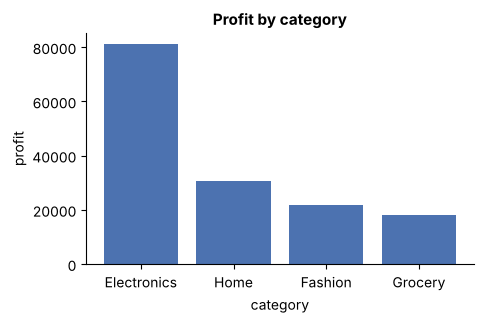

Highest-profit category: Electronics  <- *you* decide if that matters.


In [6]:
# Stage 1: data (already collected). Stage 2: transform.
def transform(df, group, measure, how="sum"):
    return df.groupby(group)[measure].agg(how).reset_index()

# Stage 3: map to graphics (an algorithm draws the image)
def map_to_graphics(table, x, y, ax):
    t = table.sort_values(y, ascending=False)
    ax.bar(t[x], t[y], color="#4C72B0")
    ax.set_xlabel(x); ax.set_ylabel(y)

table = transform(df, "category", "profit")
fig, ax = plt.subplots(figsize=(5, 3))
map_to_graphics(table, "category", "profit", ax)
ax.set_title("Profit by category")
plt.show()

# Stage 4: human perception & cognition -> pattern finding.  No code can do this for you.
print("Highest-profit category:", table.sort_values("profit").iloc[-1]["category"], " <- *you* decide if that matters.")

### 1.5 Exploration vs presentation (Wilke Ch 28)
In *exploration*, speed matters: we swap which variables map to which aesthetics and move quickly from scatter → density → boxplot → heatmap.

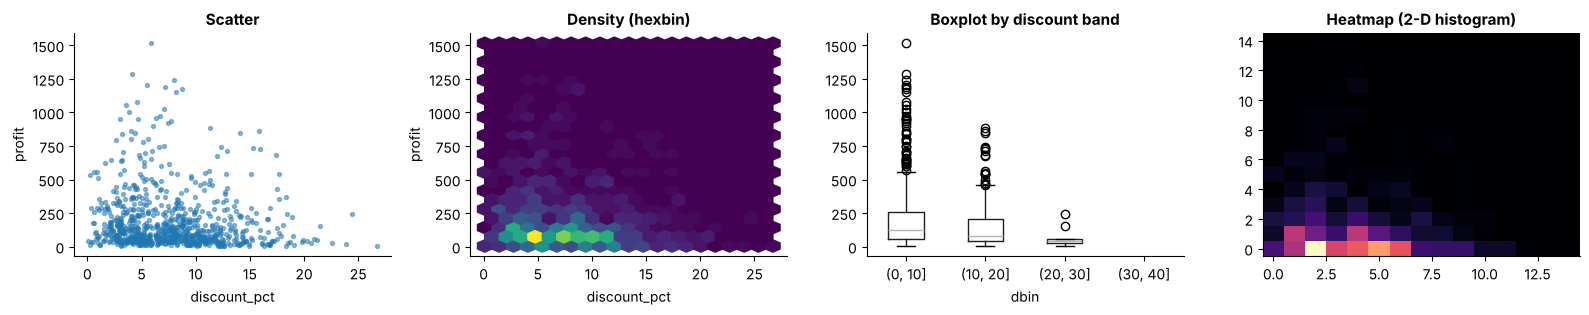

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
ax[0].scatter(df.discount_pct, df.profit, s=8, alpha=.5);          ax[0].set_title("Scatter")
hb = ax[1].hexbin(df.discount_pct, df.profit, gridsize=20, cmap="viridis");  ax[1].set_title("Density (hexbin)")
df.assign(dbin=pd.cut(df.discount_pct, [0, 10, 20, 30, 40])).boxplot(column="profit", by="dbin", ax=ax[2], grid=False)
ax[2].set_title("Boxplot by discount band"); plt.suptitle("")
h2 = np.histogram2d(df.discount_pct, df.profit, bins=15)[0]
ax[3].imshow(h2.T, origin="lower", aspect="auto", cmap="magma"); ax[3].set_title("Heatmap (2-D histogram)")
for a in ax[:2]: a.set_xlabel("discount_pct"); a.set_ylabel("profit")
plt.tight_layout(); plt.show()

---
# Topic 2 · The Automation Pipeline
**What** data? → **Why** (which task)? → **How** (marks + channels)?
The system reads columns, infers types, matches them to legal channels, infers/asks the task, picks a chart, then adds emphasis.

### 2.1 Step 1 — Data abstraction: attribute types
Wilke's types: quantitative continuous / discrete, categorical unordered / ordered, date-time, text.
Rule of thumb: **categorical → only `=`/`≠` → identity channels**; **ordered → `<`,`>` (and arithmetic) → magnitude channels.**

In [8]:
ORDERED_HINTS = {"satisfaction": ["Low", "Medium", "High"],
                 "month": ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]}

def infer_type(name, s):
    """A tiny type-inference engine in the spirit of Show Me / Draco."""
    if pd.api.types.is_datetime64_any_dtype(s):
        return "Date / time"
    if re.search(r"(_id|_code)$", name):                       # trap: digits, but an identifier
        return "Categorical unordered (key - label only)"
    if name in ORDERED_HINTS:
        return "Categorical ordered"
    if pd.api.types.is_numeric_dtype(s):
        return "Quantitative discrete" if pd.api.types.is_integer_dtype(s) else "Quantitative continuous"
    return "Categorical unordered"

CHANNEL_FOR = {   # good first-choice channel per type (slide 12)
    "Date / time": "x position",
    "Categorical unordered (key - label only)": "label only",
    "Categorical ordered": "x position (keep order!)",
    "Quantitative discrete": "x/y position",
    "Quantitative continuous": "y position",
    "Categorical unordered": "hue / region",
}

types = pd.DataFrame({"column": df.columns,
                      "pandas dtype": [str(df[c].dtype) for c in df.columns],
                      "inferred type": [infer_type(c, df[c]) for c in df.columns]})
types["good channel"] = types["inferred type"].map(CHANNEL_FOR)
types

,column,pandas dtype,inferred type,good channel
0,order_date,datetime64[us],Date / time,x position
1,month,str,Categorical ordered,x position (keep order!)
2,region,str,Categorical unordered,hue / region
3,store_code,int64,Categorical unordered (key - label only),label only
4,category,str,Categorical unordered,hue / region
5,satisfaction,str,Categorical ordered,x position (keep order!)
6,units,int64,Quantitative discrete,x/y position
7,discount_pct,float64,Quantitative continuous,y position
8,revenue,float64,Quantitative continuous,y position
9,profit,float64,Quantitative continuous,y position


### 2.2 Worked example: the two **traps for tools**
1. `store_code` contains digits but is **not a number** — averaging it is meaningless.
2. `month` is **ordered** — a tool must keep Jan → Dec, not alphabetical (Apr, Aug, Dec …).

Mean of store_code (meaningless!): 2532.0


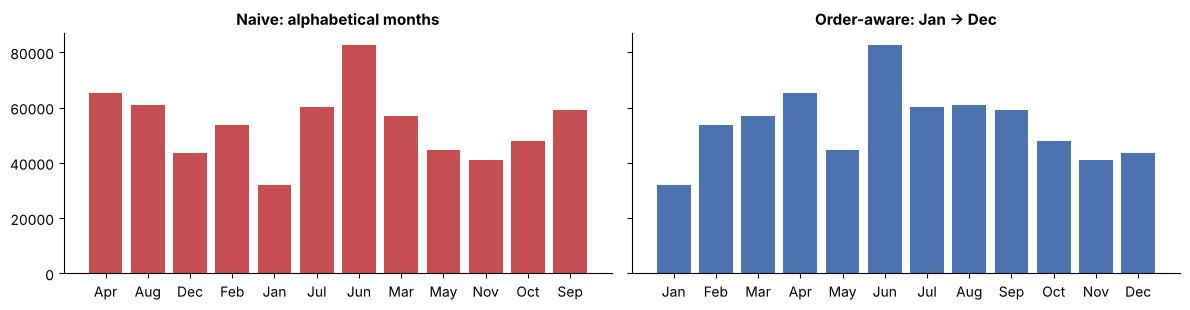

In [9]:
print("Mean of store_code (meaningless!):", round(df.store_code.mean(), 1))

months = ORDERED_HINTS["month"]
naive  = df.groupby("month")["revenue"].sum()                                  # alphabetical
proper = df.assign(month=pd.Categorical(df.month, months, ordered=True)).groupby("month", observed=False)["revenue"].sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
ax[0].bar(naive.index, naive.values, color="#C44E52");   ax[0].set_title("Naive: alphabetical months")
ax[1].bar(proper.index.astype(str), proper.values, color="#4C72B0"); ax[1].set_title("Order-aware: Jan -> Dec")
plt.tight_layout(); plt.show()

### 2.3 Step 2 — Aesthetics and scales
> *"All data visualizations map data values into quantifiable features of the resulting graphic. We refer to these features as aesthetics."* — Wilke

* **Continuous or discrete:** position, size, colour, line width. **Discrete only:** shape, line type.
* **Scales must be one-to-one:** each data value → exactly one aesthetic value and vice versa.

In [10]:
DISCRETE_ONLY = {"shape", "linetype"}

def check_mapping(field_kind, aesthetic, value_to_aes):
    """field_kind: 'continuous' or 'discrete'.  value_to_aes: dict data value -> aesthetic value."""
    problems = []
    if field_kind == "continuous" and aesthetic in DISCRETE_ONLY:
        problems.append(f"'{aesthetic}' is discrete-only; cannot encode a continuous field")
    aes_values = list(value_to_aes.values())
    if len(set(aes_values)) < len(aes_values):
        dupes = {v for v in aes_values if aes_values.count(v) > 1}
        problems.append(f"not one-to-one: several data values share {sorted(dupes)}")
    return problems or ["OK"]

print(check_mapping("discrete", "hue", {"North": "blue", "South": "orange", "East": "green", "West": "red"}))
print(check_mapping("discrete", "hue", {"North": "blue", "South": "blue",   "East": "green", "West": "red"}))
print(check_mapping("continuous", "shape", {}))

['OK']
["not one-to-one: several data values share ['blue']"]
["'shape' is discrete-only; cannot encode a continuous field"]


### 2.4 Same data, two valid mappings (slide 14)

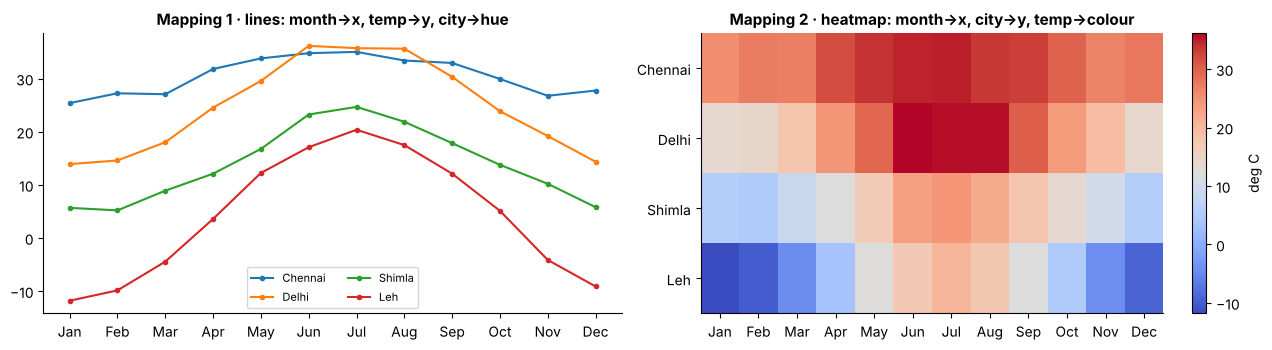

In [11]:
# synthetic monthly temperature (deg C) for 4 cities
cities = {"Chennai": (30, 4), "Delhi": (25, 12), "Shimla": (14, 9), "Leh": (4, 16)}
m_idx = np.arange(12)
temps = pd.DataFrame({c: base + amp * np.sin((m_idx - 3) / 12 * 2 * np.pi) + rng.normal(0, .8, 12)
                      for c, (base, amp) in cities.items()}, index=months)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for c in temps: ax[0].plot(months, temps[c], marker="o", ms=3, label=c)
ax[0].set_title("Mapping 1 · lines: month->x, temp->y, city->hue"); ax[0].legend(ncol=2, fontsize=8)
im = ax[1].imshow(temps.T.values, aspect="auto", cmap="coolwarm")
ax[1].set_xticks(range(12)); ax[1].set_xticklabels(months); ax[1].set_yticks(range(4)); ax[1].set_yticklabels(temps.columns)
ax[1].set_title("Mapping 2 · heatmap: month->x, city->y, temp->colour"); plt.colorbar(im, ax=ax[1], label="deg C")
plt.tight_layout(); plt.show()

* **Lines** — best for exact values and each city's annual curve.
* **Heatmap** — temperature on colour needs large areas; best for comparing seasons across cities *at a glance*.

### 2.5 Step 3 — Chart selection: the chart directory (Wilke Ch 5)

In [12]:
CHART_DIRECTORY = {
    "amounts":       ["bar", "dot plot", "heatmap"],
    "distributions": ["histogram", "density", "boxplot", "violin", "ridgeline"],
    "proportions":   ["pie", "side-by-side bar", "stacked bar", "treemap"],
    "x-y relationships": ["scatter", "bubble", "line", "correlogram"],
    "geospatial":    ["choropleth", "cartogram"],
    "uncertainty":   ["error bars", "confidence bands"],
}
def directory(goal): return CHART_DIRECTORY.get(goal, ["(unknown goal) -> ask the user"])

for g in ["amounts", "distributions", "uncertainty", "sentiment"]:
    print(f"{g:18s} -> {directory(g)}")

amounts            -> ['bar', 'dot plot', 'heatmap']
distributions      -> ['histogram', 'density', 'boxplot', 'violin', 'ridgeline']
uncertainty        -> ['error bars', 'confidence bands']
sentiment          -> ['(unknown goal) -> ask the user']


---
# Topic 3 · Automatic Selection of Marks, Channels and Chart Types
### 3.1 Marks and channels

In [13]:
marks = pd.DataFrame({"Mark": ["Point", "Line", "Area", "Link"],
                      "Dimension": ["0D", "1D", "2D", "connection / containment"],
                      "Example in a chart": ["scatter dot", "line chart", "bar / region", "network edge, nested boxes"]})
display(marks)

# Rank tables (lower rank = more effective).  Used by the greedy encoder below.
MAGNITUDE_RANK = {"x position": 1, "y position": 1, "length": 3, "angle": 4, "area": 5,
                  "volume": 6, "luminance": 7, "saturation": 8}        # for ORDERED attributes
IDENTITY_RANK  = {"region": 1, "hue": 2, "motion": 3, "shape": 4}      # for CATEGORICAL attributes
CHANNEL_RANK = {**MAGNITUDE_RANK, **IDENTITY_RANK}
pd.DataFrame({"Magnitude channels (HOW MUCH)": list(MAGNITUDE_RANK), "rank": list(MAGNITUDE_RANK.values())}).join(
    pd.DataFrame({"Identity channels (WHAT/WHERE)": list(IDENTITY_RANK) + [""] * 4,
                  "rank ": list(IDENTITY_RANK.values()) + [""] * 4}))

,Mark,Dimension,Example in a chart
0,Point,0D,scatter dot
1,Line,1D,line chart
2,Area,2D,bar / region
3,Link,connection / containment,"network edge, nested boxes"


,Magnitude channels (HOW MUCH),rank,Identity channels (WHAT/WHERE),rank
0,x position,1,region,1
1,y position,1,hue,2
2,length,3,motion,3
3,angle,4,shape,4
4,area,5,,
5,volume,6,,
6,luminance,7,,
7,saturation,8,,


### 3.2 Expressiveness (a filter) and effectiveness (a ranking)
* **Expressiveness** — encode *all of, and only,* the information in the attribute. Ordered data must look ordered; unordered data must **not**.
* **Effectiveness** — important attributes get salient channels (aligned position first).

In [14]:
def is_expressive(kind, channel):
    """kind: 'N' nominal, 'O' ordinal, 'Q' quantitative."""
    if kind == "N":                       # unordered must not look ordered
        return channel not in {"luminance", "saturation", "length", "area", "volume", "angle"}
    if kind in {"O", "Q"}:                # ordered must look ordered -> no identity-only channels
        return channel not in {"hue", "shape", "motion", "region"}
    raise ValueError(kind)

proposals = [
    ("Sales",   "Q", "length"),
    ("Region",  "N", "luminance"),
    ("Profit",  "Q", "area"),
    ("Satisfaction (Low/Med/High)", "O", "hue"),
]
rows = []
for field, kind, ch in proposals:
    ok = is_expressive(kind, ch)
    verdict = "Reject (hard)" if not ok else ("Accept" if CHANNEL_RANK[ch] <= 3 else "Accept - but rank low")
    rows.append((field, kind, ch, "Yes" if ok else "No", CHANNEL_RANK[ch], verdict))
pd.DataFrame(rows, columns=["Field", "Type", "Channel", "Expressive?", "Rank", "Verdict"])

,Field,Type,Channel,Expressive?,Rank,Verdict
0,Sales,Q,length,Yes,3,Accept
1,Region,N,luminance,No,7,Reject (hard)
2,Profit,Q,area,Yes,5,Accept - but rank low
3,Satisfaction (Low/Med/High),O,hue,No,2,Reject (hard)


### 3.3 Why these rankings? Stevens' power law  `S = Iⁿ`
`n = 1` (length): perceived = actual. `n < 1` (area, brightness): differences look **smaller**. `n > 1` (saturation): **exaggerated**.
Cleveland & McGill: position > length > angle > area.

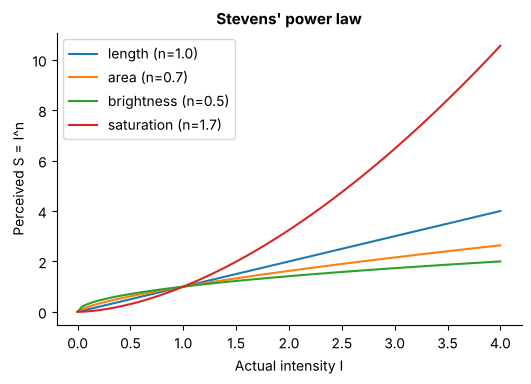

In [15]:
I = np.linspace(0, 4, 100)
exps = {"length (n=1.0)": 1.0, "area (n=0.7)": 0.7, "brightness (n=0.5)": 0.5, "saturation (n=1.7)": 1.7}
plt.figure(figsize=(6, 3.8))
for lab, n_ in exps.items(): plt.plot(I, I**n_, label=lab)
plt.xlabel("Actual intensity I"); plt.ylabel("Perceived S = I^n"); plt.legend(); plt.title("Stevens' power law")
plt.show()

### Numerical 1 · Stevens' law: company B's revenue is **double** A's

In [16]:
n_area, n_len, n_sat, ratio = 0.7, 1.0, 1.7, 2

print(f"(a) area  : B looks {ratio**n_area:.2f}x bigger  -> only {100*(ratio**n_area-1):.0f}% bigger, not 100%")
print(f"(b) length: B looks {ratio**n_len:.2f}x bigger  -> accurate")
print(f"(c) area must grow {ratio**(1/n_area):.2f}x for B to LOOK 2x")
print(f"(d) saturation: B looks {ratio**n_sat:.2f}x  -> exaggerated")
print()
print("MCQ 2 check: bubble area tripled ->", round(3**0.7, 2), "x bigger (slide answer 2.16)")

(a) area  : B looks 1.62x bigger  -> only 62% bigger, not 100%
(b) length: B looks 2.00x bigger  -> accurate
(c) area must grow 2.69x for B to LOOK 2x
(d) saturation: B looks 3.25x  -> exaggerated

MCQ 2 check: bubble area tripled -> 2.16 x bigger (slide answer 2.16)


### 3.4 Numerical 2 · Greedy encoding assignment (APT-style)
Cost = Σ weight × channel rank (lower is better). Candidates that fail expressiveness are **rejected before scoring**.
Importance weights: mpg = 4, horsepower = 3, origin = 2, weight = 1 (the slide's car example — here as code).

In [17]:
weights = {"mpg": 4, "horsepower": 3, "origin": 2, "weight": 1}
kinds   = {"mpg": "Q", "horsepower": "Q", "origin": "N", "weight": "Q"}

candidates = {
    "A": {"mpg": "y position", "horsepower": "x position", "origin": "hue",   "weight": "area"},
    "B": {"mpg": "area",       "horsepower": "x position", "origin": "hue",   "weight": "y position"},
    "C": {"mpg": "y position", "horsepower": "x position", "origin": "shape", "weight": "luminance"},
    "D": {"mpg": "y position", "horsepower": "x position", "origin": "luminance", "weight": "hue"},
}

def encoding_cost(enc):
    for f, ch in enc.items():
        if not is_expressive(kinds[f], ch):
            return None, f"x not expressive ({f} -> {ch})"
    return sum(weights[f] * CHANNEL_RANK[ch] for f, ch in enc.items()), ""

res = []
for name, enc in candidates.items():
    cost, why = encoding_cost(enc)
    res.append((name, cost if cost is not None else "-", why or "valid"))
res = pd.DataFrame(res, columns=["Encoding", "Cost", "Note"]); display(res)
best = min((r for r in res.itertuples() if r.Cost != "-"), key=lambda r: r.Cost)
print("Best encoding:", best.Encoding, "with cost", best.Cost)

,Encoding,Cost,Note
0,A,16,valid
1,B,28,valid
2,C,22,valid
3,D,-,x not expressive (origin -> luminance)


Best encoding: A with cost 16


### 3.5 Automatic encoding in action — enumerate → filter → score → top-k
Slide colour bands: 🟢 ≥ 0.75 · 🟡 ≥ 0.4 · 🔴 < 0.4

In [18]:
def band(score): return "🟢" if score >= .75 else ("🟡" if score >= .4 else "🔴")

# Task: show revenue (Q) per region (N). Enumerate (mark, channel_for_revenue, channel_for_region)
mark_options = {"bar": ("length", "x position"), "point": ("y position", "x position"),
                "pie": ("angle", "hue"), "bubble": ("area", "x position"), "heat strip": ("luminance", "x position")}
rows = []
for mk, (ch_q, ch_n) in mark_options.items():
    if not (is_expressive("Q", ch_q) and is_expressive("N", ch_n)): continue
    effectiveness = 1 - (CHANNEL_RANK[ch_q] - 1) / 8         # normalised 0..1
    rows.append((mk, ch_q, ch_n, round(effectiveness, 2), band(effectiveness)))
pd.DataFrame(rows, columns=["Mark", "Revenue ->", "Region ->", "Score", "Band"]).sort_values("Score", ascending=False)

,Mark,Revenue ->,Region ->,Score,Band
1,point,y position,x position,1.00,🟢
0,bar,length,x position,0.75,🟢
2,pie,angle,hue,0.62,🟡
3,bubble,area,x position,0.50,🟡
4,heat strip,luminance,x position,0.25,🔴


---
# Topic 4 · Rule-Based vs ML-Based Recommendation
### 4.1 Rule-based: APT and Tableau *Show Me*
Fields the user selects → recommended chart. **Strength:** transparent, fast, no training data. **Weakness:** hand-written rules miss context.

In [19]:
def field_kind(s, name=""):
    if pd.api.types.is_datetime64_any_dtype(s): return "T"
    if re.search(r"(_id|_code)$", name): return "N"
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10: return "Q"
    return "N"

SHOW_ME = {   # (sorted kinds, task) -> chart
    ("NQ", "compare"): "bar",   ("QT", "trend"): "line",   ("QQ", "correlation"): "scatter",
    ("Q", "distribution"): "histogram",  ("NQ", "part-to-whole"): "pie",
    ("NNQ", "compare"): "heatmap",
}
def show_me(df, fields, task="compare"):
    key = "".join(sorted(field_kind(df[f], f) for f in fields))
    chart = SHOW_ME.get((key, task), "ask the user")
    return chart, f"rule fired: {key} + {task!r} -> {chart}"

for fields, task in [(["category", "revenue"], "compare"), (["order_date", "revenue"], "trend"),
                     (["discount_pct", "profit"], "correlation"), (["revenue"], "distribution"),
                     (["region", "category", "revenue"], "compare"), (["category", "revenue"], "outliers")]:
    print(f"{str(fields):42s} {task:13s} ->", show_me(df, fields, task)[1])

['category', 'revenue']                    compare       -> rule fired: NQ + 'compare' -> bar
['order_date', 'revenue']                  trend         -> rule fired: QT + 'trend' -> line
['discount_pct', 'profit']                 correlation   -> rule fired: QQ + 'correlation' -> scatter
['revenue']                                distribution  -> rule fired: Q + 'distribution' -> histogram
['region', 'category', 'revenue']          compare       -> rule fired: NNQ + 'compare' -> heatmap
['category', 'revenue']                    outliers      -> rule fired: NQ + 'outliers' -> ask the user


Note how the last call returns **"ask the user"** — a good rule-based tool asks instead of guessing — and how the output *cites the rule that fired* (high explainability).

### 4.2 Constraint-based: Draco
* **Hard constraint** = expressiveness (never allowed). **Soft constraint** = effectiveness preference (allowed, but costs).
* Best chart = `argmin(cost)` over all valid specs.

### Numerical 3 · Draco-style cost computation
Task: *show how horsepower relates to mpg for cars from 3 origins.*

In [20]:
soft_w = {"s1: aggregation hides points (task=correlation)": 5,
          "s2: categorical field on colour": 1,
          "s3: quantitative field on size": 4,
          "s4: each encoding beyond 2 (clutter)": 2}
S1, S2, S3, S4 = soft_w.keys()

# violation COUNTS per candidate; None means a HARD constraint was violated
cands = {
    "A: scatter x=hp, y=mpg, colour=origin":            {S2: 1, S4: 1},
    "B: A + size=weight":                               {S2: 1, S3: 1, S4: 2},
    "C: bar, mean mpg by origin":                       {S1: 1},
    "D: scatter, shape=hp (quantitative on shape)":     None,
}
def draco_cost(violations, w):
    if violations is None: return None
    return sum(cnt * w[c] for c, cnt in violations.items())

def rank(w):
    out = [(k, draco_cost(v, w)) for k, v in cands.items()]
    valid = sorted([o for o in out if o[1] is not None], key=lambda o: o[1])
    rows = [(k, int(c)) for k, c in valid] + [(k, "invalid (hard)") for k, c in out if c is None]
    return pd.DataFrame(rows, columns=["Candidate", "Cost"])

print("Default weights:"); display(rank(soft_w))

tweaked = {**soft_w, S2: 4}      # "Try: raise w(s2) from 1 to 4"
print("w(s2) = 4  ->  bar chart C now wins. Weights encode design taste:"); display(rank(tweaked))

Default weights:


,Candidate,Cost
0,"A: scatter x=hp, y=mpg, colour=origin",3
1,"C: bar, mean mpg by origin",5
2,B: A + size=weight,9
3,"D: scatter, shape=hp (quantitative on shape)",invalid (hard)


w(s2) = 4  ->  bar chart C now wins. Weights encode design taste:


,Candidate,Cost
0,"C: bar, mean mpg by origin",5
1,"A: scatter x=hp, y=mpg, colour=origin",6
2,B: A + size=weight,12
3,"D: scatter, shape=hp (quantitative on shape)",invalid (hard)


### 4.3 ML-based: VizML, Data2Vis, DeepEye
VizML learns chart type from dataset **features** using ~1M (dataset, chart) pairs. We can't download Plotly's corpus, so we
**simulate a tiny corpus**: generate synthetic datasets, extract features, and label them with a "crowd habit" (noisy rules).

Corpus size: 3000  chart labels: {np.str_('bar'): 1048, 'line': 934, np.str_('scatter'): 528, 'histogram': 348, np.str_('pie'): 142}
Top-1 accuracy on held-out datasets: 0.876


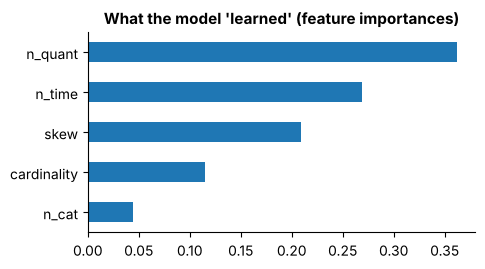

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

def make_corpus(m=3000, seed=0):
    r = np.random.default_rng(seed)
    X, y = [], []
    for _ in range(m):
        n_cat, n_quant, n_time = r.integers(0, 3), r.integers(0, 3), r.integers(0, 2)
        if n_cat + n_quant + n_time == 0: n_quant = 1
        card = r.integers(2, 30) if n_cat else 0           # cardinality of the categorical field
        skew = r.normal(0, 1) if n_quant else 0
        X.append([n_cat, n_quant, n_time, card, skew])
        # --- labels: expert-ish rules + messy "habits" in the corpus ---
        if n_time and n_quant:               lab = "line"
        elif n_cat and n_quant == 1:         lab = "bar" if card <= 12 else r.choice(["bar", "pie"], p=[.6, .4])  # bad habit: pie w/ many slices
        elif n_quant == 2 and not n_cat:     lab = "scatter"
        elif n_quant == 1 and not n_cat:     lab = "histogram"
        elif n_cat >= 1 and n_quant >= 2:    lab = "scatter"
        else:                                lab = "bar"
        if r.random() < 0.08: lab = r.choice(["bar", "line", "scatter", "histogram", "pie"])   # label noise
        y.append(lab)
    return pd.DataFrame(X, columns=["n_cat", "n_quant", "n_time", "cardinality", "skew"]), pd.Series(y, name="chart")

Xc, yc = make_corpus()
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=.25, random_state=1)
model = RandomForestClassifier(n_estimators=150, random_state=1).fit(Xtr, ytr)
print("Corpus size:", len(Xc), " chart labels:", yc.value_counts().to_dict())
print("Top-1 accuracy on held-out datasets:", round(model.score(Xte, yte), 3))
pd.Series(model.feature_importances_, index=Xc.columns).sort_values().plot.barh(figsize=(5, 2.6), title="What the model 'learned' (feature importances)")
plt.show()

In [22]:
# Predict for a NEW dataset: 1 categorical field with 20 categories + 1 quantitative field
new = pd.DataFrame([[1, 1, 0, 20, 0.0]], columns=Xc.columns)
proba = pd.Series(model.predict_proba(new)[0], index=model.classes_).sort_values(ascending=False)
print(proba.round(3).to_string())
print()
print("Rule-based Show Me says 'bar'.  The ML model gives pie a non-zero share because the CORPUS contains that bad habit.")

bar          0.613
pie          0.387
histogram    0.000
line         0.000
scatter      0.000

Rule-based Show Me says 'bar'.  The ML model gives pie a non-zero share because the CORPUS contains that bad habit.


### 4.4 Rule/constraint-based vs ML-based — side by side

In [23]:
pd.DataFrame({
    "Aspect": ["Knowledge source", "Training data", "Explainability", "New chart types", "Bias risk", "Examples"],
    "Rule / constraint-based": ["Experts, perception research", "None needed", "High: cite the rule fired",
                                "Only if a rule is added", "Designer's assumptions", "APT, Show Me, CompassQL, Draco"],
    "ML-based": ["Large corpora of existing charts", "Thousands to millions of examples", "Low: learned weights",
                 "Only if seen in training", "Copies bad habits in the corpus", "VizML, Data2Vis, DeepEye"],
}).set_index("Aspect")

,Rule / constraint-based,ML-based
Aspect,,
Knowledge source,"Experts, perception research",Large corpora of existing charts
Training data,None needed,Thousands to millions of examples
Explainability,High: cite the rule fired,Low: learned weights
New chart types,Only if a rule is added,Only if seen in training
Bias risk,Designer's assumptions,Copies bad habits in the corpus
Examples,"APT, Show Me, CompassQL, Draco","VizML, Data2Vis, DeepEye"


**Hybrid trend:** interpretable constraints with *weights learned from data* (Draco-Learn); LLMs add language on top.

### Numerical 4 · Evaluating a recommender: Hit@k and MRR
`Hit@k = (1/N) Σ 1[rankᵢ ≤ k]`   ·   `MRR = (1/N) Σ 1/rankᵢ` (0 if absent)

In [24]:
def hit_at_k(ranks, k):  return np.mean([r is not None and r <= k for r in ranks])
def mrr(ranks):          return np.mean([0 if r is None else 1 / r for r in ranks])

# slide example: expert chart vs top-3 recommended
slide = pd.DataFrame({"Dataset": ["D1", "D2", "D3", "D4", "D5"],
                      "Expert": ["bar", "scatter", "line", "histogram", "pie"],
                      "Top-3": [["bar","line","pie"], ["line","scatter","bar"], ["line","area","bar"],
                                ["bar","box","scatter"], ["bar","stacked bar","pie"]]})
def rank_of(row): return row.Top_3.index(row.Expert) + 1 if row.Expert in row.Top_3 else None
slide["Rank"] = [rank_of(r) for r in slide.rename(columns={"Top-3": "Top_3"}).itertuples()]
slide["1/rank"] = slide.Rank.apply(lambda r: 0 if pd.isna(r) else round(1 / r, 3))
display(slide)

ranks = [None if pd.isna(r) else int(r) for r in slide.Rank]
print(f"Hit@1 = {hit_at_k(ranks,1):.2f}   Hit@3 = {hit_at_k(ranks,3):.2f}   MRR = {mrr(ranks):.3f}")
print("Interpretation: right chart is usually in the top 3 but first only 40% of the time -> show a gallery.")
print()
print("MCQ 6 check (ranks 1, 2, not found, 1): MRR =", mrr([1, 2, None, 1]))

,Dataset,Expert,Top-3,Rank,1/rank
0,D1,bar,"[bar, line, pie]",1.0,1.000
1,D2,scatter,"[line, scatter, bar]",2.0,0.500
2,D3,line,"[line, area, bar]",1.0,1.000
3,D4,histogram,"[bar, box, scatter]",NaN,0.000
4,D5,pie,"[bar, stacked bar, pie]",3.0,0.333


Hit@1 = 0.40   Hit@3 = 0.80   MRR = 0.567
Interpretation: right chart is usually in the top 3 but first only 40% of the time -> show a gallery.

MCQ 6 check (ranks 1, 2, not found, 1): MRR = 0.625


In [25]:
# MCQ 8: R1 (Hit@1=.60, Hit@3=.70) vs R2 (Hit@1=.40, Hit@3=.95) for a gallery of 3
for name, h1, h3 in [("R1", .60, .70), ("R2", .40, .95)]:
    print(f"{name}: right chart on screen with a 3-chart gallery {h3:.0%} of the time")
print("-> R2 is better for a 3-chart gallery.")

R1: right chart on screen with a 3-chart gallery 70% of the time
R2: right chart on screen with a 3-chart gallery 95% of the time
-> R2 is better for a 3-chart gallery.


---
# Topic 5 · Task- and Data-Aware Chart Recommendation
> *"A tool that serves well for one task can be poorly suited for another, for exactly the same dataset."* — Munzner §1.9

* **Data-aware:** types, cardinality, distribution. **Task-aware:** also *what the user wants to do* (from a question, a click, or a menu).

### 5.1 Task × Data → Chart recommendation table

In [26]:
cols = ["1 categorical + 1 quantitative", "1 temporal + 1 quantitative", "2 quantitative", "1 quantitative"]
TASK_TABLE = pd.DataFrame(
    [["Sorted bar chart",            "Grouped bars by period", "Paired dot / slope chart", "Dot plot"],
     ["—",                           "Line chart",             "Scatter + smooth line",    "—"],
     ["Boxplot / violin per category","Ridgeline over time",   "2D density / hexbin",      "Histogram / density"],
     ["Pie / stacked bar (few parts)","Stacked area",          "—",                        "—"],
     ["—",                           "Connected scatter",      "Scatter plot",             "—"],
     ["Strip / boxplot",             "Line with highlighted points", "Scatter with highlight", "Boxplot"]],
    index=["Compare values", "See trend", "Distribution", "Part-to-whole", "Correlation", "Find outliers"], columns=cols)
display(TASK_TABLE)

def task_aware(data_shape, task):
    ans = TASK_TABLE.loc[task, data_shape]
    return ans if ans != "—" else "combination rarely meaningful -> ask the user to clarify"

print(task_aware(cols[1], "See trend"));  print(task_aware(cols[0], "See trend"))

,1 categorical + 1 quantitative,1 temporal + 1 quantitative,2 quantitative,1 quantitative
Compare values,Sorted bar chart,Grouped bars by period,Paired dot / slope chart,Dot plot
See trend,—,Line chart,Scatter + smooth line,—
Distribution,Boxplot / violin per category,Ridgeline over time,2D density / hexbin,Histogram / density
Part-to-whole,Pie / stacked bar (few parts),Stacked area,—,—
Correlation,—,Connected scatter,Scatter plot,—
Find outliers,Strip / boxplot,Line with highlighted points,Scatter with highlight,Boxplot


Line chart
combination rarely meaningful -> ask the user to clarify


### 5.2 Same data, different task → different best chart

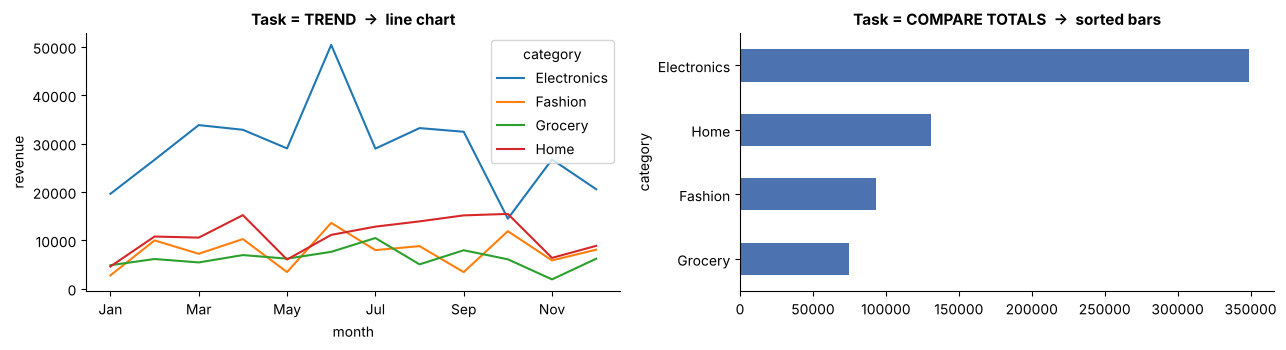

In [27]:
monthly = (df.assign(month=pd.Categorical(df.month, months, ordered=True))
             .pivot_table(index="month", columns="category", values="revenue", aggfunc="sum", observed=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
monthly.plot(ax=ax[0]); ax[0].set_title("Task = TREND  ->  line chart"); ax[0].set_ylabel("revenue")
monthly.sum().sort_values().plot.barh(ax=ax[1], color="#4C72B0"); ax[1].set_title("Task = COMPARE TOTALS  ->  sorted bars")
plt.tight_layout(); plt.show()

### Numerical 5 · Task-aware scoring
Data: monthly revenue of 3 products for 12 months. **Score = 0.6 × task_fit + 0.4 × data_fit.**

In [28]:
fit = pd.DataFrame({"data_fit":        [0.90, 0.85, 0.80, 0.30],
                    "task_fit_trend":  [0.95, 0.75, 0.60, 0.10],
                    "task_fit_compare":[0.40, 0.50, 0.90, 0.70]},
                   index=["Line", "Stacked area", "Grouped bar", "Pie"])
for t in ["trend", "compare"]:
    fit[f"score_{t}"] = (0.6 * fit[f"task_fit_{t}"] + 0.4 * fit["data_fit"]).round(2)
display(fit)
for t in ["trend", "compare"]:
    print(f"Task = {t:8s} ->", " > ".join(f"{i} ({s})" for i, s in fit[f"score_{t}"].sort_values(ascending=False).items()))

,data_fit,task_fit_trend,task_fit_compare,score_trend,score_compare
Line,0.90,0.95,0.4,0.93,0.60
Stacked area,0.85,0.75,0.5,0.79,0.64
Grouped bar,0.80,0.60,0.9,0.68,0.86
Pie,0.30,0.10,0.7,0.18,0.54


Task = trend    -> Line (0.93) > Stacked area (0.79) > Grouped bar (0.68) > Pie (0.18)
Task = compare  -> Grouped bar (0.86) > Stacked area (0.64) > Line (0.6) > Pie (0.54)


---
# Topic 6 · Visualization Search and Recommendation
### 6.1 Design as search
Munzner: most of the design space is ineffective → **satisfice** (find *one of many good* solutions), consider multiple alternatives.
A recommender enlarges your consideration space and filters out poor solutions *before you see them*.

### Numerical 6 · How big is the design space?
3 fields (2 Q, 1 N) · 6 channels · 4 mark types · 4 transformations per quantitative field (raw / binned / mean / sum).

In [29]:
def n_specs(n_fields, n_quant, channels=6, marks=4, transforms=4):
    return math.perm(channels, n_fields) * marks * transforms ** n_quant

a = n_specs(3, 2); b = n_specs(5, 4)
print(f"(a) 3 fields: P(6,3) x 4 x 4^2 = {math.perm(6,3)} x 4 x 16 = {a:,}")
print(f"(b) 5 fields: P(6,5) x 4 x 4^4 = {math.perm(6,5)} x 4 x 256 = {b:,}")

(a) 3 fields: P(6,3) x 4 x 4^2 = 120 x 4 x 16 = 7,680
(b) 5 fields: P(6,5) x 4 x 4^4 = 720 x 4 x 256 = 737,280


### 6.2 Enumerate → prune (hard constraints) → rank (soft cost): a CompassQL-style engine
We enumerate **all** specs for the field set `(revenue: Q, profit: Q, region: N)` and watch pruning shrink the space.

In [30]:
CHANNELS = ["x position", "y position", "hue", "size(area)", "shape", "facet"]
RANK = {"x position": 1, "y position": 1, "hue": 2, "size(area)": 5, "shape": 4, "facet": 3}
MARKS = ["point", "bar", "line", "area"]
TRANSFORMS = ["raw", "binned", "mean", "sum"]
fields = {"revenue": "Q", "profit": "Q", "region": "N"}

def ok_hard(field_kind_, channel):                       # expressiveness
    if field_kind_ == "Q" and channel in {"shape", "hue", "facet"}: return False
    if field_kind_ == "N" and channel == "size(area)": return False
    return True

all_specs = [dict(zip(fields, ch)) | {"mark": mk, "t_" + list(fields)[0]: t1, "t_" + list(fields)[1]: t2}
             for ch in itertools.permutations(CHANNELS, 3)
             for mk in MARKS for t1 in TRANSFORMS for t2 in TRANSFORMS]
print("Enumerated specs        :", f"{len(all_specs):,}")

valid = [s for s in all_specs if all(ok_hard(k, s[f]) for f, k in fields.items())]
print("After hard constraints  :", f"{len(valid):,}")

IMPORTANCE = {"revenue": 3, "profit": 3, "region": 1}
def soft_cost(s):
    c = sum(IMPORTANCE[f] * RANK[s[f]] for f in fields)
    c += 4 if s["mark"] == "area" else (2 if s["mark"] == "line" else 0)           # mark preference for non-temporal x
    c += sum(1 for k in s if k.startswith("t_") and s[k] in {"sum", "mean"})      # aggregation hides points
    return c

ranked = sorted(valid, key=soft_cost)
top = pd.DataFrame(ranked[:5])[["revenue", "profit", "region", "mark", "t_revenue", "t_profit"]]
top["cost"] = [soft_cost(s) for s in ranked[:5]]
print("Top-5 by lowest cost:"); display(top)

Enumerated specs        : 7,680
After hard constraints  : 1,408
Top-5 by lowest cost:


,revenue,profit,region,mark,t_revenue,t_profit,cost
0,x position,y position,hue,point,raw,raw,8
1,x position,y position,hue,point,raw,binned,8
2,x position,y position,hue,point,binned,raw,8
3,x position,y position,hue,point,binned,binned,8
4,x position,y position,hue,bar,raw,raw,8


### 6.3 Voyager-style gallery (CompassQL with wildcards)
Voyager: user picks fields (or none) → query like `mark = ?, x = hp, y = ?` → engine enumerates, prunes, ranks → a **gallery** with the top chart per field set.
Goal: *breadth-first exploration; avoid fixating early.* We implement a drawing function for each chart type and let the Show-Me rules fill the gallery.

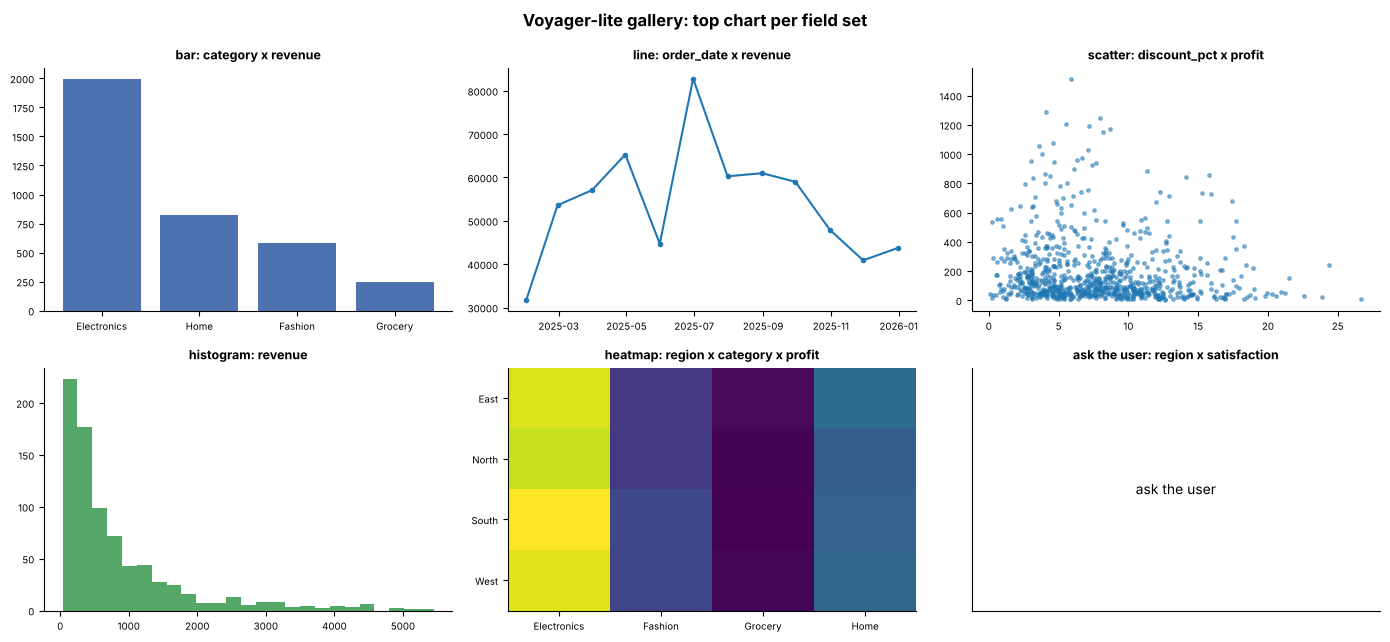

In [31]:
def draw(ax, df, fields, chart):
    f = fields
    if chart == "bar":
        t = df.groupby(f[0])[f[1]].mean().sort_values(ascending=False); ax.bar(t.index.astype(str), t.values, color="#4C72B0")
    elif chart == "line":
        t = df.set_index(f[0])[f[1]].resample("ME").sum(); ax.plot(t.index, t.values, marker="o", ms=3)
    elif chart == "scatter":
        ax.scatter(df[f[0]], df[f[1]], s=6, alpha=.5)
    elif chart == "histogram":
        ax.hist(df[f[0]], bins=25, color="#55A868")
    elif chart == "heatmap":
        pv = df.pivot_table(index=f[0], columns=f[1], values=f[2], aggfunc="mean"); ax.imshow(pv.values, cmap="viridis", aspect="auto")
        ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(pv.columns, fontsize=7); ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index, fontsize=7)
    elif chart == "pie":
        t = df.groupby(f[0])[f[1]].sum(); ax.pie(t.values, labels=t.index)
    else:
        ax.text(.5, .5, "ask the user", ha="center", va="center"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{chart}: {' x '.join(f)}", fontsize=9)
    ax.tick_params(labelsize=7)

gallery = [(["category", "revenue"], "compare"), (["order_date", "revenue"], "trend"),
           (["discount_pct", "profit"], "correlation"), (["revenue"], "distribution"),
           (["region", "category", "profit"], "compare"), (["region", "satisfaction"], "compare")]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, (fl, task) in zip(axes.ravel(), gallery):
    chart, _ = show_me(df, fl, task); draw(ax, df, fl, chart)
plt.suptitle("Voyager-lite gallery: top chart per field set", fontweight="bold"); plt.tight_layout(); plt.show()

The last panel says **"ask the user"** — `region` and `satisfaction` are both categorical and no rule covers a count/crosstab. That's the gap the *hands-on* section asks you to close.

*Click a chart → related views (add a field / change encoding).* A tiny version of "related views": given a field set, suggest one extra field to add.

In [32]:
def related_views(df, fields, task="compare"):
    out = []
    for extra in [c for c in df.columns if c not in fields and c not in {"month"}]:
        chart, why = show_me(df, fields + [extra], task)
        if chart != "ask the user": out.append((extra, chart))
    return out
print("Add a field to ['category','revenue']:", related_views(df, ["category", "revenue"]))

Add a field to ['category','revenue']: [('region', 'heatmap'), ('store_code', 'heatmap'), ('satisfaction', 'heatmap'), ('units', 'heatmap')]


---
# Topic 7 · Text-to-Chart Generation (LIDA, NL4DV, Chat2VIS)
**How it works:** the prompt contains *question + data schema + a few sample rows* → an LLM writes code (pandas + matplotlib) → code runs → chart returned. No manual field picking.

To keep this notebook offline and deterministic we use a **mock LLM** — a function that pattern-matches the question and returns plausible code. Everything *around* it (prompt building, code execution, validation) is the real pipeline.

In [33]:
def build_prompt(question, df, n_rows=3):
    schema = "\n".join(f"- {c} ({df[c].dtype})" for c in df.columns)
    sample = df.head(n_rows).to_csv(index=False)
    return (f"You are a visualization assistant. Write matplotlib code using the DataFrame `df`.\n"
            f"Schema:\n{schema}\nSample rows:\n{sample}\nQuestion: {question}\nReturn only Python code.")

prompt = build_prompt("Which category earns the most profit?", df)
print(prompt)

You are a visualization assistant. Write matplotlib code using the DataFrame `df`.
Schema:
- order_date (datetime64[us])
- month (str)
- region (str)
- store_code (int64)
- category (str)
- satisfaction (str)
- units (int64)
- discount_pct (float64)
- revenue (float64)
- profit (float64)
Sample rows:
order_date,month,region,store_code,category,satisfaction,units,discount_pct,revenue,profit
2025-01-02,Jan,North,1103,Home,Medium,8,7.7,1236.35,194.36
2025-01-02,Jan,North,1103,Fashion,Medium,2,3.2,219.05,48.56
2025-01-03,Jan,South,2201,Grocery,Medium,1,1.2,34.86,9.74

Question: Which category earns the most profit?
Return only Python code.


Q: Which category earns the most profit?


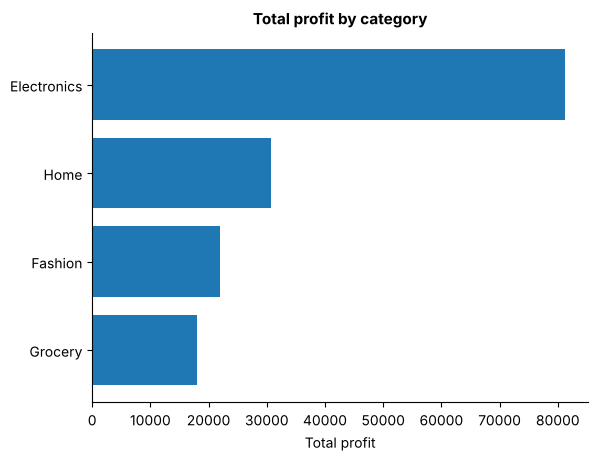

Q: Show the revenue trend over time


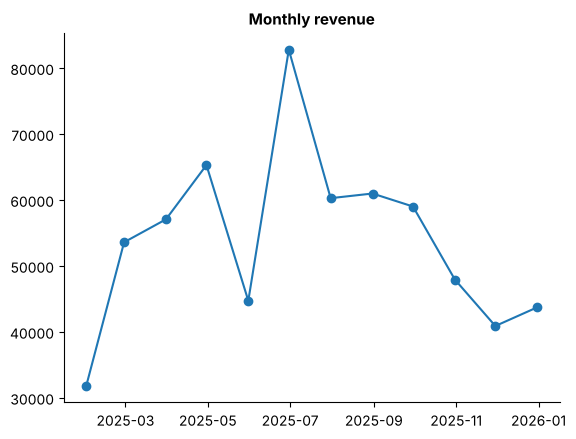

In [34]:
def mock_llm(prompt):
    """Stand-in for an LLM: returns code for a handful of question patterns (and sometimes gets it wrong)."""
    q = prompt.split("Question:")[-1].lower()
    if "happiness" in q:                                      # hallucinated column
        return "fig, ax = plt.subplots()\ndf.groupby('region')['happiness_score'].mean().plot.bar(ax=ax)\nax.set_title('Happiness by region')"
    if "profit" in q and "category" in q:
        return ("fig, ax = plt.subplots()\nt = df.groupby('category')['profit'].sum().sort_values()\n"
                "ax.barh(t.index, t.values)\nax.set_xlabel('Total profit')\nax.set_title('Total profit by category')")
    if "trend" in q or "over time" in q:
        return ("fig, ax = plt.subplots()\nt = df.set_index('order_date')['revenue'].resample('ME').sum()\n"
                "ax.plot(t.index, t.values, marker='o')\nax.set_title('Monthly revenue')")
    if "average revenue" in q:                                # wrong aggregation: sum instead of mean
        return ("fig, ax = plt.subplots()\nt = df.groupby('region')['revenue'].sum()\n"
                "ax.bar(t.index, t.values)\nax.set_title('Average revenue by region')")
    return "raise ValueError('I could not understand the question')"

def validate_code(code_str, df):
    """Cheap guard-rail: flag columns referenced in code that do not exist in the data."""
    used = set(re.findall(r"\[['\"](\w+)['\"]\]", code_str)) | set(re.findall(r"groupby\(['\"](\w+)['\"]\)", code_str))
    missing = sorted(used - set(df.columns))
    return missing

def text_to_chart(question, df):
    code_str = mock_llm(build_prompt(question, df))
    print(f"Q: {question}")
    missing = validate_code(code_str, df)
    if missing:
        print(f"   !! hallucinated column(s): {missing} -> not executing\n"); return
    try:
        exec(code_str, {"df": df, "pd": pd, "np": np, "plt": plt})
        plt.show()
    except Exception as e:
        print("   !! generated code crashed:", type(e).__name__, e)

text_to_chart("Which category earns the most profit?", df)
text_to_chart("Show the revenue trend over time", df)

### Typical failure modes (slide 36): *code that crashes · wrong aggregation · hallucinated columns · misleading titles*

In [35]:
text_to_chart("Plot average happiness by region", df)           # hallucinated column
text_to_chart("Predict next year's weather", df)                # crashes

Q: Plot average happiness by region
   !! hallucinated column(s): ['happiness_score'] -> not executing

Q: Predict next year's weather
   !! generated code crashed: ValueError I could not understand the question


Q: Show average revenue by region


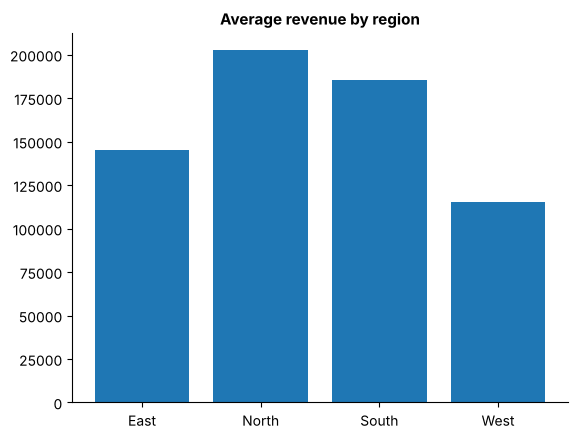

Sum  per region : {'East': 145416.0, 'North': 202412.0, 'South': 185278.0, 'West': 115032.0}
Mean per region : {'East': 831.0, 'North': 833.0, 'South': 813.0, 'West': 747.0}
-> the chart looks fine, the title says 'average', but the numbers are totals. Only a human who checks the code catches this.


In [36]:
# Wrong aggregation + misleading title: asks for AVERAGE revenue, the (mock) LLM plots SUM, but titles it 'Average'
text_to_chart("Show average revenue by region", df)
print("Sum  per region :", df.groupby("region")["revenue"].sum().round(0).to_dict())
print("Mean per region :", df.groupby("region")["revenue"].mean().round(0).to_dict())
print("-> the chart looks fine, the title says 'average', but the numbers are totals. Only a human who checks the code catches this.")

**Why it is still promising:** works from a plain question, any library, and can *propose goals the user did not think of*.
**Save the generated code/spec** and the chart becomes reproducible.

---
# Topic 8 · Advantages and Limitations of Automation
| Advantages | Limitations |
|---|---|
| **Speed** – charts in seconds | **No domain context** – can't know which question matters |
| **Better defaults** – perceptual rankings applied consistently | **Task guessed wrongly; types mis-inferred** |
| **Breadth** – enlarges the consideration space | **Rigid rules / corpus habits / hallucination** |
| **Accessibility** – plain-language questions | **Over-trust** – users accept the first chart |
| **Scale** – many fields & datasets | **Validation is hard** – metrics ≠ human judgement |
| **Reproducible** if spec/code is saved | **Generic, presentation-poor** charts without polish |

### 8.1 Over-trust demo: the "first chart" can mislead
A tool that defaults to `mean` hides how the points are distributed. Same field set, two aggregations — which one would you *accept at first glance*?

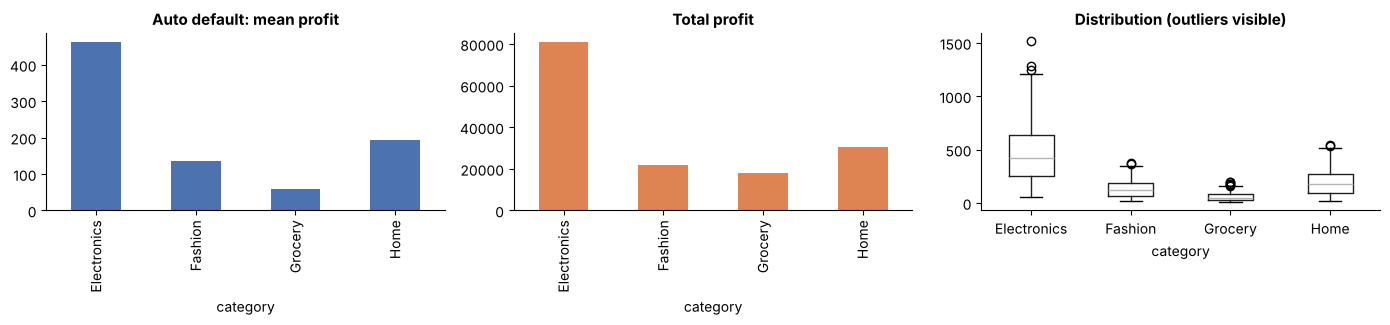

In [37]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
df.groupby("category")["profit"].mean().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Auto default: mean profit")
df.groupby("category")["profit"].sum().plot.bar(ax=ax[1], color="#DD8452");  ax[1].set_title("Total profit")
df.boxplot(column="profit", by="category", ax=ax[2], grid=False);            ax[2].set_title("Distribution (outliers visible)")
plt.suptitle(""); plt.tight_layout(); plt.show()

### 8.2 Keep the human in the loop — a 6-point checklist

In [38]:
def audit(spec, df):
    """Run the slide-38 checklist on a chart spec. spec: dict(fields=[(name, channel)], task, agg, title)."""
    res = {}
    cols = [f for f, _ in spec["fields"]]
    res["1 Right data?"]    = all(c in df.columns for c in cols) and (spec.get("agg") in {None, "mean", "sum", "count"})
    res["2 Right types?"]   = not any(re.search(r"(_id|_code)$", c) and spec.get("agg") in {"mean", "sum"} for c in cols)
    kinds = {c: ("O" if c in ORDERED_HINTS else field_kind(df[c], c)) for c in cols}
    res["3 Expressive?"]    = all(is_expressive(kinds[f], ch) for f, ch in spec["fields"])
    key = [f for f, _ in spec["fields"] if kinds[f] in {"Q"}]
    res["4 Effective?"]     = all(CHANNEL_RANK[ch] <= 3 for f, ch in spec["fields"] if f in key[:1])
    ok_task = {"compare": {"bar", "dot"}, "trend": {"line"}, "distribution": {"histogram", "boxplot"}}
    res["5 Fits the task?"] = spec.get("chart") in ok_task.get(spec["task"], {spec.get("chart")})
    res["6 Low cognitive cost?"] = len(spec["fields"]) <= 3 and spec.get("chart") != "pie"
    return pd.Series(res).map({True: "✅", False: "❌"})

good = dict(fields=[("region", "x position"), ("revenue", "length")], task="compare", chart="bar", agg="mean")
bad  = dict(fields=[("store_code", "luminance"), ("revenue", "area")], task="compare", chart="bubble", agg="mean")
pd.DataFrame({"Good auto-chart": audit(good, df), "Questionable auto-chart": audit(bad, df)})

,Good auto-chart,Questionable auto-chart
1 Right data?,✅,✅
2 Right types?,✅,❌
3 Expressive?,✅,❌
4 Effective?,✅,❌
5 Fits the task?,✅,❌
6 Low cognitive cost?,✅,✅


---
# Hands-On · A Mini Rule-Based Recommender
The slide's starter code, run on our dataset. Steps from the lecture: **run 5 field/task pairs → score with the 6-point checklist → add one rule your tool was missing.**

In [39]:
def col_type(s):
    if pd.api.types.is_datetime64_any_dtype(s): return 'T'
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10:
        return 'Q'
    return 'N'                     # categorical / ordinal

def recommend(df, fields, task='compare'):
    t = ''.join(sorted(col_type(df[f]) for f in fields))
    rules = {('NQ', 'compare'):       'bar',
             ('QT', 'trend'):         'line',
             ('QQ', 'correlation'):   'scatter',
             ('Q',  'distribution'):  'histogram',
             ('NQ', 'part-to-whole'): 'pie'}
    return rules.get((t, task), 'ask the user')

tests = [(['region', 'revenue'], 'compare'), (['order_date', 'revenue'], 'trend'),
         (['discount_pct', 'profit'], 'correlation'), (['profit'], 'distribution'),
         (['category', 'profit'], 'part-to-whole'), (['store_code', 'revenue'], 'correlation'),
         (['category', 'revenue'], 'outliers')]
pd.DataFrame([(f, t, recommend(df, f, t)) for f, t in tests], columns=["fields", "task", "recommended"])

,fields,task,recommended
0,"[region, revenue]",compare,bar
1,"[order_date, revenue]",trend,line
2,"[discount_pct, profit]",correlation,scatter
3,[profit],distribution,histogram
4,"[category, profit]",part-to-whole,pie
5,"[store_code, revenue]",correlation,scatter
6,"[category, revenue]",outliers,ask the user


**Two bugs the audit exposes**
1. `('store_code','revenue')` → `col_type` thinks `store_code` is **Q** (12 distinct integers > 10) and returns *scatter* — the *Station-ID trap* again.
2. `('category','revenue')` + `outliers` → `ask the user` — **a rule is missing.**

Fix both and re-run:

In [40]:
import re
def col_type(s, name=""):
    if pd.api.types.is_datetime64_any_dtype(s): return 'T'
    if re.search(r"(_id|_code)$", name): return 'N'                # NEW: identifiers are labels, not numbers
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10: return 'Q'
    return 'N'

RULES = {('NQ', 'compare'): 'bar', ('QT', 'trend'): 'line', ('QQ', 'correlation'): 'scatter',
         ('Q', 'distribution'): 'histogram', ('NQ', 'part-to-whole'): 'pie',
         ('NQ', 'distribution'): 'boxplot per category',      # NEW rule
         ('NQ', 'outliers'): 'strip / boxplot',               # NEW rule
         ('Q', 'outliers'): 'boxplot'}                        # NEW rule

def recommend2(df, fields, task='compare'):
    t = ''.join(sorted(col_type(df[f], f) for f in fields))
    return RULES.get((t, task), 'ask the user')

pd.DataFrame([(f, t, recommend2(df, f, t)) for f, t in tests], columns=["fields", "task", "recommended (v2)"])

,fields,task,recommended (v2)
0,"[region, revenue]",compare,bar
1,"[order_date, revenue]",trend,line
2,"[discount_pct, profit]",correlation,scatter
3,[profit],distribution,histogram
4,"[category, profit]",part-to-whole,pie
5,"[store_code, revenue]",correlation,ask the user
6,"[category, revenue]",outliers,strip / boxplot


---
# Summary
| Topic | Take-away |
|---|---|
| Automated vis systems | Rank or generate charts from data and goals; **humans judge** |
| Pipeline | data types → task → marks & channels → chart selection |
| Marks & channels | **Expressiveness filters, effectiveness ranks** (position first) |
| Rule vs ML | APT / Show Me / Draco encode rules; VizML / Data2Vis learn from charts |
| Task/data-aware | Same data, different task → different best chart |
| Search & recommendation | Design as search; Voyager galleries enlarge the consideration space |
| Text-to-chart | LLMs write chart code from a question (LIDA) — validate it |
| Limits | Context, wrong tasks, hallucination, over-trust → **keep a human in the loop** |

**References:** Munzner *Visualization Analysis and Design* (Ch 1, 2, 5) · Wilke *Fundamentals of Data Visualization* (Ch 2, 5, 28) · Ware *Information Visualization* (Ch 1, 12) ·
Mackinlay 1986 · Mackinlay et al. 2007 · Wongsuphasawat et al. 2016 · Moritz et al. 2019 · Hu et al. 2019 · Dibia & Demiralp 2019 · Dibia 2023.